In [ ]:
!pip install -q opencv-python-headless albumentations torch torchvision matplotlib numpy

[INFO]: [ARM] 初期化
[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[0.000, 0.000, 0.000, 0.000] rad | duration=1.5s
[INFO]: [GRIPPER] 初期化
[INFO]: Publish -> /crane_plus_gripper_controller/joint_trajectory | positions=[-0.600] rad | duration=1.0s
[INFO]: ▶ シナリオ開始: Case 1: Normal

▼ 【判断用プレビュー】Case 1: Normal の初期カメラ画像とグレア抽出マスク


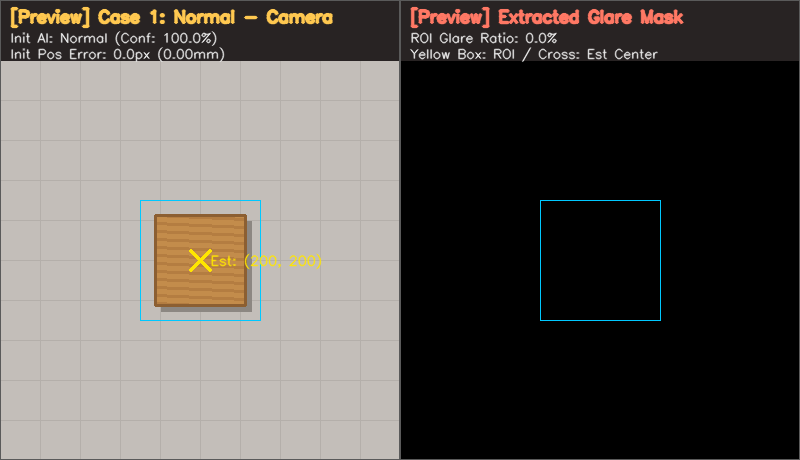

【Case 1: Normal】 AI推論結果:
  ・推論ラベル   : Normal (Level 0)
  ・確信度       : 100.0%
  ・ROI白飛び率  : 0.0%
  ・AI推奨制御   : None (Direct Pick)
--------------------------------------------------------------------
上のプレビュー画像を確認し、実行する制御アクションを選択してください:
  [1 / Enter] AI推奨アクションを実行 (None (Direct Pick))
  [2] 強制オーバーライド: OpenCV Inpaint + CLAHE のみ (ソフトウェア補正のみ)
  [3] 強制オーバーライド: Active Shadowing + Inpaint (物理遮光 + ソフトウェア補正)
  [4] 強制オーバーライド: 対策なしでそのままピック (Baseline比較用)
>>> 番号を入力 (1-4, Enterで1): 
  -> [実行結果] 適用制御: None (Direct Pick)
  -> [座標評価] 真値=(200, 200)px, 推論値=(200, 200)px | 誤差=0.0px (0.00mm) -> SUCCESS (把持成功)

[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[0.000, -0.650, -1.350, -0.600] rad | duration=1.5s
[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[0.000, -0.780, -1.420, -0.450] rad | duration=1.0s
[INFO]: Publish -> /crane_plus_gripper_controller/joint_trajectory | positions=[0.350] rad | duration=1.0s
[INFO]: Publish -> /crane_plus_arm_controller/

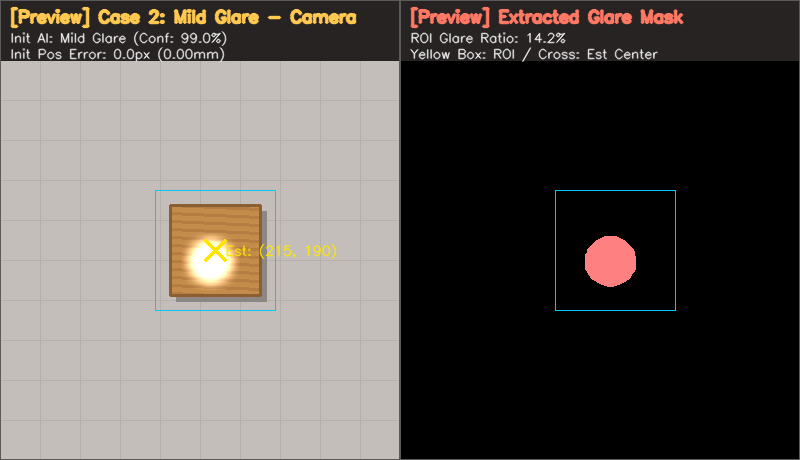

【Case 2: Mild Glare】 AI推論結果:
  ・推論ラベル   : Mild Glare (Level 1)
  ・確信度       : 99.0%
  ・ROI白飛び率  : 14.2%
  ・AI推奨制御   : OpenCV Inpaint + CLAHE
--------------------------------------------------------------------
上のプレビュー画像を確認し、実行する制御アクションを選択してください:
  [1 / Enter] AI推奨アクションを実行 (OpenCV Inpaint + CLAHE)
  [2] 強制オーバーライド: OpenCV Inpaint + CLAHE のみ (ソフトウェア補正のみ)
  [3] 強制オーバーライド: Active Shadowing + Inpaint (物理遮光 + ソフトウェア補正)
  [4] 強制オーバーライド: 対策なしでそのままピック (Baseline比較用)
>>> 番号を入力 (1-4, Enterで1): 
  -> [実行結果] 適用制御: OpenCV Inpaint (TELEA) + CLAHE
  -> [座標評価] 真値=(215, 190)px, 推論値=(215, 190)px | 誤差=0.0px (0.00mm) -> SUCCESS (把持成功)

[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[-0.041, -0.650, -1.350, -0.600] rad | duration=1.5s
[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[-0.041, -0.780, -1.420, -0.450] rad | duration=1.0s
[INFO]: Publish -> /crane_plus_gripper_controller/joint_trajectory | positions=[0.350] rad | duration=1.0s
[INFO]: Publish 

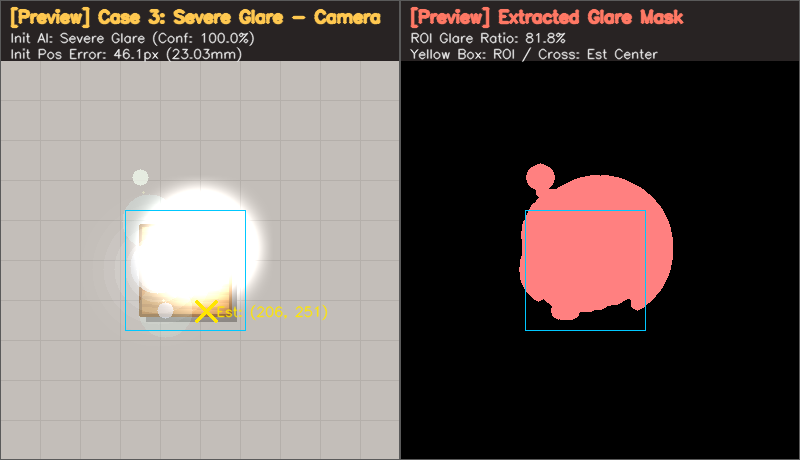

【Case 3: Severe Glare】 AI推論結果:
  ・推論ラベル   : Severe Glare (Level 2)
  ・確信度       : 100.0%
  ・ROI白飛び率  : 81.8%
  ・AI推奨制御   : Active Shadowing (Robot Arm Shade)
--------------------------------------------------------------------
上のプレビュー画像を確認し、実行する制御アクションを選択してください:
  [1 / Enter] AI推奨アクションを実行 (Active Shadowing (Robot Arm Shade))
  [2] 強制オーバーライド: OpenCV Inpaint + CLAHE のみ (ソフトウェア補正のみ)
  [3] 強制オーバーライド: Active Shadowing + Inpaint (物理遮光 + ソフトウェア補正)
  [4] 強制オーバーライド: 対策なしでそのままピック (Baseline比較用)
>>> 番号を入力 (1-4, Enterで1): 
[INFO]: [ARM] 遮光姿勢へ移動
[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[0.000, -0.350, -1.150, -0.850] rad | duration=1.2s
  -> [実行結果] 適用制御: Active Shadowing (Arm Shade)
  -> [座標評価] 真値=(185, 210)px, 推論値=(185, 210)px | 誤差=0.0px (0.00mm) -> SUCCESS (把持成功)

[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[0.043, -0.650, -1.350, -0.600] rad | duration=1.5s
[INFO]: Publish -> /crane_plus_arm_controller/joint_trajectory | positions=[

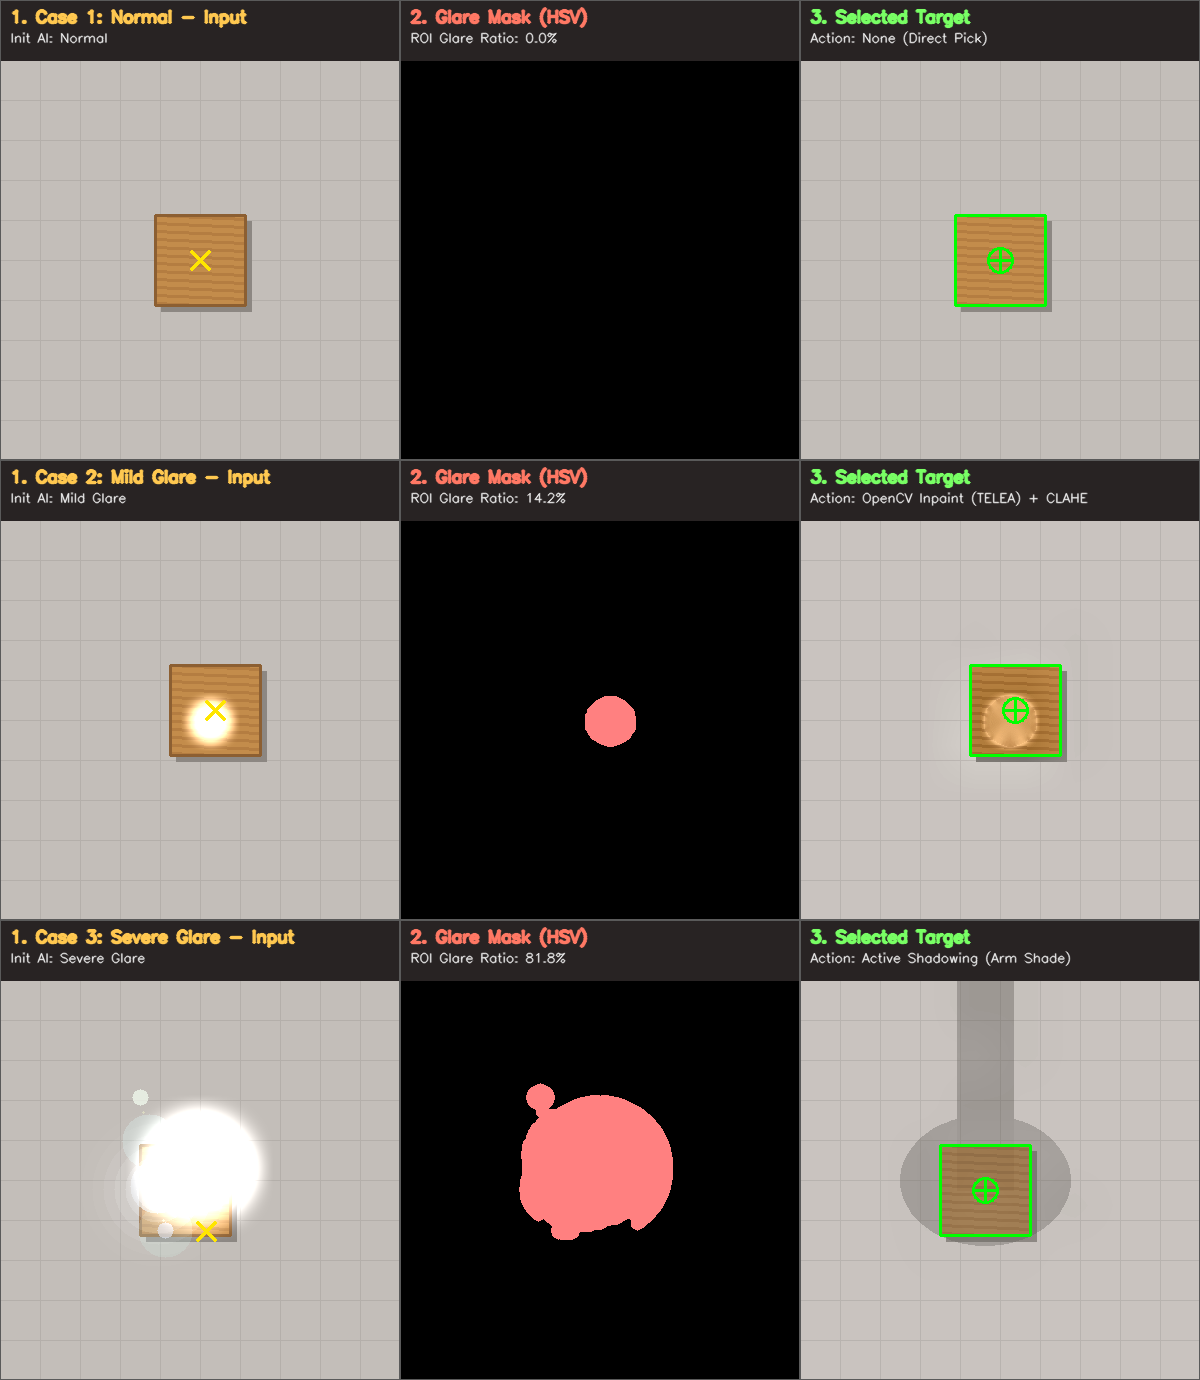


※ ピック＆プレースのアニメーションは動画 (demo_output.mp4) を確認ください。


In [ ]:
#!/usr/bin/env python3

import math
import os
import sys
import time
from dataclasses import dataclass
from typing import List, Optional, Tuple

import cv2
import numpy as np

# --- オプションライブラリのインポート ---
try:
    import albumentations as A
    HAS_ALBUMENTATIONS = True
except ImportError:
    HAS_ALBUMENTATIONS = False

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

try:
    from google.colab.patches import cv2_imshow
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# --- ROS 2 (rclpy) のインポートとモックフォールバック ---
try:
    import rclpy
    from rclpy.node import Node
    from sensor_msgs.msg import Image, JointState
    from trajectory_msgs.msg import JointTrajectory, JointTrajectoryPoint
    from builtin_interfaces.msg import Duration
    HAS_ROS2 = True
except ImportError:
    HAS_ROS2 = False

    class Duration:
        def __init__(self, sec: int = 0, nanosec: int = 0):
            self.sec = sec; self.nanosec = nanosec
    class JointTrajectoryPoint:
        def __init__(self):
            self.positions = []; self.velocities = []; self.time_from_start = Duration()
    class JointTrajectory:
        def __init__(self):
            self.joint_names = []; self.points = []
    class _MockLogger:
        def info(self, msg: str): print(f"[INFO]: {msg}")
        def warn(self, msg: str): print(f"[WARN]: {msg}")
        def error(self, msg: str): print(f"[ERROR]: {msg}")
    class _MockPublisher:
        def __init__(self, topic_name: str, node_ref: "Node"):
            self.topic_name = topic_name; self.node_ref = node_ref
        def publish(self, msg: JointTrajectory):
            if msg.points:
                pt = msg.points[0]
                pos_str = ", ".join([f"{p:.3f}" for p in pt.positions])
                t_sec = pt.time_from_start.sec + pt.time_from_start.nanosec * 1e-9
                self.node_ref.get_logger().info(
                    f"Publish -> {self.topic_name} | positions=[{pos_str}] rad | duration={t_sec:.1f}s"
                )
    class Node:
        def __init__(self, node_name: str):
            self._node_name = node_name; self._logger = _MockLogger()
        def get_logger(self): return self._logger
        def create_publisher(self, msg_type, topic: str, qos: int): return _MockPublisher(topic, self)
        def destroy_node(self): pass


# =====================================================================
# 1. データ構造とアニメーション補間
# =====================================================================
@dataclass
class InferenceResult:
    glare_level: int
    glare_label: str
    confidence: float
    cube_center_px: Tuple[int, int]
    cube_world_xy: Tuple[float, float]
    glare_ratio_on_roi: float
    glare_mask: np.ndarray


class ArmAnimator:
    """キーフレーム間のアーム手先座標とグリッパー開閉度を線形補間するクラス"""
    def __init__(self, keyframes: List[Tuple[float, int, int, float, str]]):
        self.keyframes = sorted(keyframes, key=lambda k: k[0])

    def get_state(self, t: float) -> Tuple[Tuple[int, int], float, str]:
        if t <= self.keyframes[0][0]:
            return (self.keyframes[0][1], self.keyframes[0][2]), self.keyframes[0][3], self.keyframes[0][4]
        if t >= self.keyframes[-1][0]:
            return (self.keyframes[-1][1], self.keyframes[-1][2]), self.keyframes[-1][3], self.keyframes[-1][4]

        for i in range(len(self.keyframes) - 1):
            k1, k2 = self.keyframes[i], self.keyframes[i + 1]
            if k1[0] <= t <= k2[0]:
                dt = (t - k1[0]) / (k2[0] - k1[0]) if k2[0] != k1[0] else 0.0
                px = int(k1[1] + (k2[1] - k1[1]) * dt)
                py = int(k1[2] + (k2[2] - k1[2]) * dt)
                g = k1[3] + (k2[3] - k1[3]) * dt
                return (px, py), g, k1[4]
        return (self.keyframes[-1][1], self.keyframes[-1][2]), self.keyframes[-1][3], self.keyframes[-1][4]


# =====================================================================
# 2. AI状態推論モデル ＆ OpenCVビジョン処理
# =====================================================================
class GlareStateInferenceAI:
    LABELS = {0: "Normal", 1: "Mild Glare", 2: "Severe Glare"}
    RECOMMENDED_ACTIONS = {
        0: "None (Direct Pick)",
        1: "OpenCV Inpaint + CLAHE",
        2: "Active Shadowing (Robot Arm Shade)",
    }

    def __init__(self):
        self.use_torch = HAS_TORCH
        if self.use_torch:
            torch.manual_seed(42)
            self.model = nn.Sequential(nn.Linear(6, 16), nn.ReLU(), nn.Linear(16, 3))
            self._initialize_calibrated_weights()
            self.model.eval()

    def _initialize_calibrated_weights(self):
        with torch.no_grad():
            w1 = torch.zeros((16, 6), dtype=torch.float32); b1 = torch.zeros(16, dtype=torch.float32)
            w1[0, 0] = -12.0; b1[0] = 1.2
            w1[1, 0] = 10.0; b1[1] = -0.4
            w1[2, 0] = 16.0; w1[2, 1] = 4.0; b1[2] = -5.2
            w1[3, 4] = -4.0; b1[3] = 3.0
            self.model[0].weight.copy_(w1); self.model[0].bias.copy_(b1)
            w2 = torch.zeros((3, 16), dtype=torch.float32); b2 = torch.tensor([1.5, -0.5, -2.0], dtype=torch.float32)
            w2[0, 0] = 6.0; w2[0, 1] = -3.0; w2[0, 2] = -6.0
            w2[1, 0] = -2.0; w2[1, 1] = 4.5; w2[1, 2] = -5.5
            w2[2, 0] = -5.0; w2[2, 1] = 1.0; w2[2, 2] = 9.0; w2[2, 3] = 1.5
            self.model[2].weight.copy_(w2); self.model[2].bias.copy_(b2)

    def extract_glare_mask(self, bgr_img: np.ndarray) -> np.ndarray:
        """HSV色空間で低彩度・高明度の鏡面反射（白飛び）領域を抽出する"""
        hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
        raw_mask = cv2.inRange(hsv, np.array([0, 0, 215], dtype=np.uint8), np.array([180, 65, 255], dtype=np.uint8))
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        return cv2.dilate(raw_mask, kernel, iterations=2)

    def detect_wood_cube(self, bgr_img: np.ndarray) -> Tuple[Tuple[int, int], float, np.ndarray]:
        """木目キューブ領域を抽出し、画像モーメントから重心座標と凸包面積比(Solidity)を算出する"""
        h, w = bgr_img.shape[:2]
        hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
        wood_mask = cv2.inRange(hsv, np.array([8, 45, 40], dtype=np.uint8), np.array([32, 255, 245], dtype=np.uint8))
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
        wood_mask = cv2.morphologyEx(wood_mask, cv2.MORPH_OPEN, kernel)
        wood_mask = cv2.morphologyEx(wood_mask, cv2.MORPH_CLOSE, kernel)
        contours, _ = cv2.findContours(wood_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return (w // 2, h // 2), 0.1, wood_mask
        largest_cnt = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(largest_cnt)
        if area < 50.0:
            return (w // 2, h // 2), 0.1, wood_mask
        solidity = float(area / max(cv2.contourArea(cv2.convexHull(largest_cnt)), 1.0))
        M = cv2.moments(largest_cnt)
        if M["m00"] > 1e-5:
            return (int(M["m10"] / M["m00"]), int(M["m01"] / M["m00"])), solidity, wood_mask
        return (w // 2, h // 2), solidity, wood_mask

    def pixel_to_robot_xy(self, cx: int, cy: int, img_shape: Tuple[int, int]) -> Tuple[float, float]:
        """画像座標(px)をロボットベース座標系(m)へ変換する (1px = 0.5mm)"""
        h, w = img_shape[:2]
        scale_m_per_px = 0.0005
        return (
            round(0.18 - (cy - (h / 2.0)) * scale_m_per_px, 4),
            round(0.00 - (cx - (w / 2.0)) * scale_m_per_px, 4),
        )

    def infer(self, bgr_img: np.ndarray, expected_roi_center: Optional[Tuple[int, int]] = None) -> InferenceResult:
        h, w = bgr_img.shape[:2]
        glare_mask = self.extract_glare_mask(bgr_img)
        (cx, cy), solidity, _ = self.detect_wood_cube(bgr_img)
        roi_cx, roi_cy = expected_roi_center if expected_roi_center is not None else (cx, cy)
        half_r = 60
        x1, x2 = max(0, roi_cx - half_r), min(w, roi_cx + half_r)
        y1, y2 = max(0, roi_cy - half_r), min(h, roi_cy + half_r)
        roi_glare = glare_mask[y1:y2, x1:x2]
        roi_glare_ratio = float(np.count_nonzero(roi_glare)) / float(max(roi_glare.size, 1))

        if self.use_torch:
            hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
            features = np.array([
                roi_glare_ratio,
                float(np.count_nonzero(glare_mask)) / (h * w),
                float(np.max(hsv[:, :, 2])) / 255.0,
                float(np.min(hsv[:, :, 1])) / 255.0,
                solidity,
                1.0 if roi_glare_ratio > 0.02 else 0.0,
            ], dtype=np.float32)
            with torch.no_grad():
                probs = torch.softmax(self.model(torch.from_numpy(features).unsqueeze(0)), dim=1).squeeze(0).numpy()
                glare_level = int(np.argmax(probs)); confidence = float(probs[glare_level])
        else:
            if roi_glare_ratio < 0.05: glare_level, confidence = 0, 0.96
            elif roi_glare_ratio < 0.35: glare_level, confidence = 1, 0.92
            else: glare_level, confidence = 2, 0.95

        return InferenceResult(
            glare_level, self.LABELS[glare_level], confidence,
            (cx, cy), self.pixel_to_robot_xy(cx, cy, (h, w)), roi_glare_ratio, glare_mask
        )


class GlareVisionProcessor:
    def __init__(self, img_width: int = 400, img_height: int = 400):
        self.width = img_width; self.height = img_height
        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    def generate_virtual_table_scene(self, cube_px: Tuple[int, int] = (200, 200), is_shaded_by_arm: bool = False) -> np.ndarray:
        img = np.full((self.height, self.width, 3), (185, 190, 195), dtype=np.uint8)
        for x in range(0, self.width, 40): cv2.line(img, (x, 0), (x, self.height), (170, 175, 180), 1)
        for y in range(0, self.height, 40): cv2.line(img, (0, y), (self.width, y), (170, 175, 180), 1)
        cx, cy = cube_px; half_size = 45
        cv2.rectangle(img, (cx - half_size + 6, cy - half_size + 6), (cx + half_size + 6, cy + half_size + 6), (130, 135, 140), -1)
        cube_roi = np.full((half_size * 2, half_size * 2, 3), (75, 140, 195), dtype=np.uint8)
        for i in range(0, half_size * 2, 8): cv2.line(cube_roi, (0, i), (half_size * 2, i + 4), (65, 125, 180), 2)
        y1, y2 = max(0, cy - half_size), min(self.height, cy + half_size)
        x1, x2 = max(0, cx - half_size), min(self.width, cx + half_size)
        img[y1:y2, x1:x2] = cube_roi[: (y2 - y1), : (x2 - x1)]
        cv2.rectangle(img, (x1, y1), (x2, y2), (50, 95, 140), 2)
        if is_shaded_by_arm:
            shadow = img.copy()
            cv2.ellipse(shadow, (cx, cy - 10), (85, 65), 0, 0, 360, (95, 100, 105), -1)
            cv2.rectangle(shadow, (cx - 28, 0), (cx + 28, cy), (85, 90, 95), -1)
            img = cv2.addWeighted(shadow, 0.38, img, 0.62, 0)
        return img

    def inject_random_glare(self, base_img: np.ndarray, mode: str = "mild", target_center: Tuple[int, int] = (200, 200), is_shaded_by_arm: bool = False) -> np.ndarray:
        """検証用に擬似的な鏡面反射（白飛び）をキューブ周辺へ付与する"""
        out = base_img.copy()
        if mode == "none" or is_shaded_by_arm: return out
        cx, cy = target_center
        rng = np.random.default_rng(seed=101 if mode == "mild" else 202)
        gx, gy = cx + int(rng.integers(-12, 13)), cy + int(rng.integers(-12, 13))

        if mode == "mild":
            glare_layer = np.zeros_like(out)
            cv2.circle(glare_layer, (gx, gy), 20, (255, 255, 255), -1)
            out = cv2.add(out, cv2.GaussianBlur(glare_layer, (21, 21), 8.0))
        elif mode == "severe":
            if HAS_ALBUMENTATIONS:
                try:
                    rgb = cv2.cvtColor(out, cv2.COLOR_BGR2RGB)
                    t = A.RandomSunFlare(
                        flare_roi=(max(0.0, (gx - 30) / self.width), max(0.0, (gy - 30) / self.height),
                                   min(1.0, (gx + 30) / self.width), min(1.0, (gy + 30) / self.height)),
                        src_radius=110, src_color=(255, 255, 255), p=1.0
                    )
                    out = cv2.cvtColor(t(image=rgb)["image"], cv2.COLOR_RGB2BGR)
                except Exception:
                    pass
            glare_layer = np.zeros_like(out)
            cv2.circle(glare_layer, (gx + 22, gy - 18), 52, (255, 255, 255), -1)
            out = cv2.add(out, cv2.GaussianBlur(glare_layer, (45, 45), 16.0))
            cv2.circle(out, (gx + 22, gy - 18), 38, (255, 255, 255), -1)
        return out

    def mitigate_mild_glare_by_opencv(self, glared_img: np.ndarray, glare_mask: np.ndarray) -> np.ndarray:
        """Telea法によるInpaint修復とLAB色空間でのCLAHEコントラスト強調を行う"""
        inpainted = cv2.inpaint(glared_img, glare_mask, 7, cv2.INPAINT_TELEA)
        l, a, b = cv2.split(cv2.cvtColor(inpainted, cv2.COLOR_BGR2LAB))
        return cv2.cvtColor(cv2.merge((self.clahe.apply(l), a, b)), cv2.COLOR_LAB2BGR)


# =====================================================================
# 3. 視覚プレビュー付き対話型オーバーライド ＆ 制御ノード
# =====================================================================
class GlareAwarePickAndPlaceNode(Node):
    ARM_JOINT_NAMES = ["crane_plus_joint1", "crane_plus_joint2", "crane_plus_joint3", "crane_plus_joint4"]
    GRIPPER_JOINT_NAMES = ["crane_plus_joint_hand"]
    POSE_HOME = [0.0, 0.0, 0.0, 0.0]
    POSE_ACTIVE_SHADOW = [0.0, -0.35, -1.15, -0.85]
    POSE_PRE_GRASP = [0.0, -0.65, -1.35, -0.60]
    POSE_GRASP = [0.0, -0.78, -1.42, -0.45]
    POSE_LIFT = [0.0, -0.30, -1.10, -0.70]
    POSE_PLACE = [0.70, -0.75, -1.40, -0.45]

    GRIPPER_OPEN = -0.60
    GRIPPER_CLOSE = 0.35
    MISS_THRESHOLD_PX = 12.0  # 把持成否の許容誤差閾値 (12px = 6.0mm)

    def __init__(self):
        super().__init__("glare_aware_pick_and_place_node")
        self.arm_pub = self.create_publisher(JointTrajectory, "/crane_plus_arm_controller/joint_trajectory", 10)
        self.gripper_pub = self.create_publisher(JointTrajectory, "/crane_plus_gripper_controller/joint_trajectory", 10)

        self.ai_engine = GlareStateInferenceAI()
        self.vision_proc = GlareVisionProcessor(400, 400)
        self.recorded_video_frames: List[np.ndarray] = []
        self.representative_frames: List[np.ndarray] = []

    def publish_arm_trajectory(self, positions: List[float], duration_sec: float = 2.0, desc: str = ""):
        msg = JointTrajectory(); msg.joint_names = self.ARM_JOINT_NAMES
        pt = JointTrajectoryPoint(); pt.positions = [float(p) for p in positions]
        sec = int(duration_sec); pt.time_from_start = Duration(sec=sec, nanosec=int((duration_sec - sec) * 1e9))
        msg.points.append(pt)
        if desc: self.get_logger().info(f"[ARM] {desc}")
        self.arm_pub.publish(msg)
        time.sleep(duration_sec if (HAS_ROS2 and not IN_COLAB) else 0.02)

    def publish_gripper_trajectory(self, position: float, duration_sec: float = 1.0, desc: str = ""):
        msg = JointTrajectory(); msg.joint_names = self.GRIPPER_JOINT_NAMES
        pt = JointTrajectoryPoint(); pt.positions = [float(position)]
        sec = int(duration_sec); pt.time_from_start = Duration(sec=sec, nanosec=int((duration_sec - sec) * 1e9))
        msg.points.append(pt)
        if desc: self.get_logger().info(f"[GRIPPER] {desc}")
        self.gripper_pub.publish(msg)
        time.sleep(duration_sec if (HAS_ROS2 and not IN_COLAB) else 0.02)

    def _add_header(self, img: np.ndarray, title: str, lines: List[str], color: Tuple[int, int, int]) -> np.ndarray:
        canvas = np.zeros((460, 400, 3), dtype=np.uint8)
        canvas[60:460, 0:400] = img
        cv2.rectangle(canvas, (0, 0), (400, 60), (35, 35, 40), -1)
        cv2.putText(canvas, title, (10, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2, cv2.LINE_AA)
        for idx, text in enumerate(lines):
            cv2.putText(canvas, text, (10, 42 + idx * 16), cv2.FONT_HERSHEY_SIMPLEX, 0.43, (235, 235, 235), 1, cv2.LINE_AA)
        cv2.rectangle(canvas, (0, 0), (399, 459), (90, 90, 90), 1)
        return canvas

    def render_pre_decision_preview(
        self, title: str, glared_frame: np.ndarray, init_inf: InferenceResult, true_cube_px: Tuple[int, int]
    ):
        """コンソール入力の前に、グレアのかかり具合とマスク抽出状態を視覚表示する"""
        h, w = glared_frame.shape[:2]
        half_r = 60
        rx1, rx2 = max(0, true_cube_px[0] - half_r), min(w, true_cube_px[0] + half_r)
        ry1, ry2 = max(0, true_cube_px[1] - half_r), min(h, true_cube_px[1] + half_r)

        # 左パネル: 初期カメラ画像 + ROI枠(水色) + 初期推論重心(黄色クロス)
        vis_input = glared_frame.copy()
        cv2.rectangle(vis_input, (rx1, ry1), (rx2, ry2), (255, 200, 0), 1)
        cv2.drawMarker(vis_input, init_inf.cube_center_px, (0, 230, 255), cv2.MARKER_TILTED_CROSS, 20, 2)
        cv2.putText(
            vis_input, f"Est: {init_inf.cube_center_px}",
            (init_inf.cube_center_px[0] + 10, init_inf.cube_center_px[1] + 5),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 230, 255), 1, cv2.LINE_AA
        )

        # 右パネル: 抽出されたグレアマスク(赤色強調) + ROI枠
        vis_mask = cv2.cvtColor(init_inf.glare_mask, cv2.COLOR_GRAY2BGR)
        red_tint = np.zeros_like(vis_mask)
        red_tint[:, :, 2] = init_inf.glare_mask
        vis_mask = cv2.addWeighted(vis_mask, 0.5, red_tint, 0.5, 0)
        cv2.rectangle(vis_mask, (rx1, ry1), (rx2, ry2), (255, 200, 0), 1)

        init_err_px = math.hypot(init_inf.cube_center_px[0] - true_cube_px[0], init_inf.cube_center_px[1] - true_cube_px[1])
        p_left = self._add_header(
            vis_input, f"[Preview] {title} - Camera",
            [f"Init AI: {init_inf.glare_label} (Conf: {init_inf.confidence*100:.1f}%)",
             f"Init Pos Error: {init_err_px:.1f}px ({init_err_px*0.5:.2f}mm)"],
            (80, 200, 255)
        )
        p_right = self._add_header(
            vis_mask, "[Preview] Extracted Glare Mask",
            [f"ROI Glare Ratio: {init_inf.glare_ratio_on_roi*100:.1f}%",
             "Yellow Box: ROI / Cross: Est Center"],
            (100, 120, 255)
        )
        preview_combined = np.hstack([p_left, p_right])

        print(f"\n▼ 【判断用プレビュー】{title} の初期カメラ画像とグレア抽出マスク")
        if IN_COLAB:
            cv2_imshow(preview_combined)
            # IOPubチャネルの画像描画完了を待ってからinput()を呼ぶための同期処理
            sys.stdout.flush()
            time.sleep(0.3)
        elif os.environ.get("DISPLAY"):
            cv2.imshow("Pre-Decision Glare Preview", preview_combined)
            cv2.waitKey(100)

    def prompt_user_action_override(
        self, title: str, glared_frame: np.ndarray, init_inf: InferenceResult, true_cube_px: Tuple[int, int]
    ) -> int:
        """プレビュー画像とAI推論結果を表示し、コンソールから制御アクションの選択を受け付ける"""
        self.render_pre_decision_preview(title, glared_frame, init_inf, true_cube_px)

        rec_action = self.ai_engine.RECOMMENDED_ACTIONS[init_inf.glare_level]
        print("=" * 68)
        print(f"【{title}】 AI推論結果:")
        print(f"  ・推論ラベル   : {init_inf.glare_label} (Level {init_inf.glare_level})")
        print(f"  ・確信度       : {init_inf.confidence * 100:.1f}%")
        print(f"  ・ROI白飛び率  : {init_inf.glare_ratio_on_roi * 100:.1f}%")
        print(f"  ・AI推奨制御   : {rec_action}")
        print("-" * 68)
        print("上のプレビュー画像を確認し、実行する制御アクションを選択してください:")
        print(f"  [1 / Enter] AI推奨アクションを実行 ({rec_action})")
        print("  [2] 強制オーバーライド: OpenCV Inpaint + CLAHE のみ (ソフトウェア補正のみ)")
        print("  [3] 強制オーバーライド: Active Shadowing + Inpaint (物理遮光 + ソフトウェア補正)")
        print("  [4] 強制オーバーライド: 対策なしでそのままピック (Baseline比較用)")
        sys.stdout.flush()

        while True:
            choice = input(">>> 番号を入力 (1-4, Enterで1): ").strip()
            if choice in ["", "1"]:
                return init_inf.glare_level
            elif choice == "2":
                return 1
            elif choice == "3":
                return 2
            elif choice == "4":
                return 0
            print("[WARN] 1〜4の番号を入力してください。")

    def draw_anim_arm(self, img: np.ndarray, end_effector: Tuple[int, int], gripper_ratio: float, state_txt: str, is_miss_carry: bool = False):
        h, w = img.shape[:2]
        base_px = (w // 2, h + 15)
        mid_px = (int((base_px[0] + end_effector[0]) / 2) + 35, int((base_px[1] + end_effector[1]) / 2) - 10)

        cv2.line(img, base_px, mid_px, (130, 135, 140), 16, cv2.LINE_AA)
        cv2.line(img, mid_px, end_effector, (100, 105, 110), 12, cv2.LINE_AA)
        cv2.circle(img, mid_px, 12, (60, 65, 70), -1, cv2.LINE_AA)

        ex, ey = end_effector
        cv2.circle(img, (ex, ey), 10, (40, 45, 50), -1, cv2.LINE_AA)

        if gripper_ratio < 0.2 and not is_miss_carry and state_txt in ["Pick", "Lift", "Move", "Place"]:
            half_size = 45
            cube_roi = np.full((half_size * 2, half_size * 2, 3), (75, 140, 195), dtype=np.uint8)
            for i in range(0, half_size * 2, 8):
                cv2.line(cube_roi, (0, i), (half_size * 2, i + 4), (65, 125, 180), 2)
            y1, y2 = max(0, ey - half_size), min(h, ey + half_size)
            x1, x2 = max(0, ex - half_size), min(w, ex + half_size)
            if y2 > y1 and x2 > x1:
                img[y1:y2, x1:x2] = cube_roi[: (y2 - y1), : (x2 - x1)]
                cv2.rectangle(img, (x1, y1), (x2, y2), (50, 95, 140), 2)

        angle = math.atan2(ey - mid_px[1], ex - mid_px[0])
        claw_len = 50
        claw_open_angle = 0.25 + 0.4 * gripper_ratio
        for sign in [-1, 1]:
            cx = int(ex + claw_len * math.cos(angle + sign * claw_open_angle))
            cy = int(ey + claw_len * math.sin(angle + sign * claw_open_angle))
            cv2.line(img, (ex, ey), (cx, cy), (40, 40, 220), 4, cv2.LINE_AA)

        if state_txt:
            color = (0, 0, 255) if "Miss" in state_txt else (255, 200, 50)
            cv2.putText(img, state_txt, (end_effector[0] + 15, end_effector[1] - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

    def generate_scenario_animation(
        self, title: str, init_inf: InferenceResult, final_inf: InferenceResult,
        action_str: str, base_frame: np.ndarray, restored_frame: np.ndarray,
        true_cube_px: Tuple[int, int], is_final_miss: bool
    ):
        fps = 24
        duration = 6.0
        total_frames = int(fps * duration)
        h, w = 400, 400
        home_px = (w // 2, h - 30)
        place_px = (60, 200)

        p1_tgt = init_inf.cube_center_px
        p1_hov = (p1_tgt[0], p1_tgt[1] - 40)
        is_init_miss = (init_inf.glare_level > 0)
        p1_pick_txt = "Miss Pick!" if is_init_miss else "Pick"

        p1_keys = [
            (0.0, home_px[0], home_px[1], 1.0, "Wait"),
            (0.2, p1_hov[0], p1_hov[1], 1.0, "Approach"),
            (0.3, p1_tgt[0], p1_tgt[1], 1.0, "Grasp"),
            (0.4, p1_tgt[0], p1_tgt[1], 0.0, p1_pick_txt),
            (0.5, p1_hov[0], p1_hov[1], 0.0, "Lift"),
            (0.7, place_px[0], place_px[1] - 40, 0.0, "Move"),
            (0.8, place_px[0], place_px[1], 0.0, "Place"),
            (0.85, place_px[0], place_px[1], 1.0, "Release"),
            (1.0, home_px[0], home_px[1], 1.0, "Home"),
        ]
        anim1 = ArmAnimator(p1_keys)

        p3_tgt = final_inf.cube_center_px
        p3_hov = (p3_tgt[0], p3_tgt[1] - 40)
        p3_pick_txt = "Miss Pick!" if is_final_miss else "Pick"

        if "Shadowing" in action_str:
            shadow_px = (p3_tgt[0] + 10, p3_tgt[1] + 30)
            p3_keys = [
                (0.0, home_px[0], home_px[1], 1.0, "Wait"),
                (0.15, shadow_px[0], shadow_px[1], 1.0, "Shadowing"),
                (0.35, shadow_px[0], shadow_px[1], 1.0, "Shadowing"),
                (0.45, p3_hov[0], p3_hov[1], 1.0, "Approach"),
                (0.55, p3_tgt[0], p3_tgt[1], 1.0, "Grasp"),
                (0.65, p3_tgt[0], p3_tgt[1], 0.0, p3_pick_txt),
                (0.75, p3_hov[0], p3_hov[1], 0.0, "Lift"),
                (0.85, place_px[0], place_px[1] - 40, 0.0, "Move"),
                (0.9, place_px[0], place_px[1], 0.0, "Place"),
                (0.95, place_px[0], place_px[1], 1.0, "Release"),
                (1.0, home_px[0], home_px[1], 1.0, "Home"),
            ]
        else:
            p3_keys = [
                (0.0, home_px[0], home_px[1], 1.0, "Wait"),
                (0.2, p3_hov[0], p3_hov[1], 1.0, "Approach"),
                (0.3, p3_tgt[0], p3_tgt[1], 1.0, "Grasp"),
                (0.4, p3_tgt[0], p3_tgt[1], 0.0, p3_pick_txt),
                (0.5, p3_hov[0], p3_hov[1], 0.0, "Lift"),
                (0.7, place_px[0], place_px[1] - 40, 0.0, "Move"),
                (0.8, place_px[0], place_px[1], 0.0, "Place"),
                (0.85, place_px[0], place_px[1], 1.0, "Release"),
                (1.0, home_px[0], home_px[1], 1.0, "Home"),
            ]
        anim3 = ArmAnimator(p3_keys)

        def erase_cube(img, cx, cy):
            cv2.rectangle(img, (cx - 55, cy - 55), (cx + 55, cy + 55), (185, 190, 195), -1)
            for x in range(0, img.shape[1], 40):
                if cx - 55 <= x <= cx + 55: cv2.line(img, (x, max(0, cy - 55)), (x, min(img.shape[0], cy + 55)), (170, 175, 180), 1)
            for y in range(0, img.shape[0], 40):
                if cy - 55 <= y <= cy + 55: cv2.line(img, (max(0, cx - 55), y), (min(img.shape[1], cx + 55), y), (170, 175, 180), 1)

        def draw_placed_cube(img, cx, cy):
            half_size = 45
            cv2.rectangle(img, (cx - half_size + 6, cy - half_size + 6), (cx + half_size + 6, cy + half_size + 6), (130, 135, 140), -1)
            cube_roi = np.full((half_size * 2, half_size * 2, 3), (75, 140, 195), dtype=np.uint8)
            for i in range(0, half_size * 2, 8): cv2.line(cube_roi, (0, i), (half_size * 2, i + 4), (65, 125, 180), 2)
            y1, y2 = max(0, cy - half_size), min(img.shape[0], cy + half_size)
            x1, x2 = max(0, cx - half_size), min(img.shape[1], cx + half_size)
            if y2 > y1 and x2 > x1:
                img[y1:y2, x1:x2] = cube_roi[: (y2 - y1), : (x2 - x1)]
                cv2.rectangle(img, (x1, y1), (x2, y2), (50, 95, 140), 2)

        animated_frames = []
        for f in range(total_frames):
            t = f / float(total_frames - 1)
            p1_pos, p1_grip, p1_txt = anim1.get_state(t)
            p3_pos, p3_grip, p3_txt = anim3.get_state(t)

            img1 = base_frame.copy()
            if p1_txt in ["Pick", "Lift", "Move", "Place"] and not is_init_miss:
                erase_cube(img1, true_cube_px[0], true_cube_px[1])
            if p1_txt in ["Release", "Home"] and not is_init_miss:
                erase_cube(img1, true_cube_px[0], true_cube_px[1])
                draw_placed_cube(img1, place_px[0], place_px[1])
            cv2.drawMarker(img1, p1_tgt, (0, 230, 255), cv2.MARKER_TILTED_CROSS, 18, 2)
            cv2.circle(img1, place_px, 15, (0, 165, 255), 2, cv2.LINE_AA)
            self.draw_anim_arm(img1, p1_pos, p1_grip, p1_txt, is_miss_carry=(p1_grip < 0.2 and is_init_miss))

            img2 = cv2.cvtColor(init_inf.glare_mask, cv2.COLOR_GRAY2BGR)
            red_tint = np.zeros_like(img2); red_tint[:, :, 2] = init_inf.glare_mask
            img2 = cv2.addWeighted(img2, 0.5, red_tint, 0.5, 0)

            img3 = restored_frame.copy()
            if p3_txt in ["Pick", "Lift", "Move", "Place"] and not is_final_miss:
                erase_cube(img3, true_cube_px[0], true_cube_px[1])
            if p3_txt in ["Release", "Home"] and not is_final_miss:
                erase_cube(img3, true_cube_px[0], true_cube_px[1])
                draw_placed_cube(img3, place_px[0], place_px[1])

            marker_color = (0, 0, 255) if is_final_miss else (0, 255, 0)
            cv2.drawMarker(img3, p3_tgt, marker_color, cv2.MARKER_CROSS, 22, 2)
            cv2.circle(img3, place_px, 15, (0, 165, 255), 2, cv2.LINE_AA)
            self.draw_anim_arm(img3, p3_pos, p3_grip, p3_txt, is_miss_carry=(p3_grip < 0.2 and is_final_miss))

            c1 = self._add_header(img1, f"1. {title} - Input", [f"Init AI: {init_inf.glare_label} ({init_inf.confidence*100:.0f}%)"], (80, 200, 255))
            c2 = self._add_header(img2, "2. Glare Mask (HSV)", [f"ROI Glare Ratio: {init_inf.glare_ratio_on_roi*100:.1f}%"], (100, 120, 255))
            c3_color = (80, 80, 255) if is_final_miss else (100, 255, 120)
            c3 = self._add_header(img3, "3. Selected Action Result", [f"Action: {action_str}"], c3_color)

            combined = np.hstack([c1, c2, c3])
            animated_frames.append(combined)

        pre_wait_frames = [animated_frames[0]] * int(fps * 1.0)
        post_wait_frames = [animated_frames[-1]] * int(fps * 0.5)
        self.recorded_video_frames.extend(pre_wait_frames + animated_frames + post_wait_frames)

        static_img1 = base_frame.copy()
        cv2.drawMarker(static_img1, p1_tgt, (0, 230, 255), cv2.MARKER_TILTED_CROSS, 18, 2)

        static_img2 = cv2.cvtColor(init_inf.glare_mask, cv2.COLOR_GRAY2BGR)
        static_red = np.zeros_like(static_img2); static_red[:, :, 2] = init_inf.glare_mask
        static_img2 = cv2.addWeighted(static_img2, 0.5, static_red, 0.5, 0)

        static_img3 = restored_frame.copy()
        marker_color = (0, 0, 255) if is_final_miss else (0, 255, 0)
        cv2.drawMarker(static_img3, p3_tgt, marker_color, cv2.MARKER_CROSS, 22, 2)
        cv2.circle(static_img3, p3_tgt, 12, marker_color, 2)
        cv2.rectangle(static_img3, (p3_tgt[0] - 45, p3_tgt[1] - 45), (p3_tgt[0] + 45, p3_tgt[1] + 45), marker_color, 2)

        sc1 = self._add_header(static_img1, f"1. {title} - Input", [f"Init AI: {init_inf.glare_label}"], (80, 200, 255))
        sc2 = self._add_header(static_img2, "2. Glare Mask (HSV)", [f"ROI Glare Ratio: {init_inf.glare_ratio_on_roi*100:.1f}%"], (100, 120, 255))
        sc3 = self._add_header(static_img3, "3. Selected Target", [f"Action: {action_str}"], (80, 80, 255) if is_final_miss else (100, 255, 120))

        self.representative_frames.append(np.hstack([sc1, sc2, sc3]))

    def execute_single_scenario(self, title: str, glare_mode: str, true_cube_px: Tuple[int, int]):
        """1シナリオ分の推論・視覚プレビュー表示・コンソール介入・制御を実行する"""
        self.get_logger().info(f"▶ シナリオ開始: {title}")
        base_frame = self.vision_proc.generate_virtual_table_scene(cube_px=true_cube_px, is_shaded_by_arm=False)
        glared_frame = self.vision_proc.inject_random_glare(base_frame, mode=glare_mode, target_center=true_cube_px)

        init_inf = self.ai_engine.infer(glared_frame, expected_roi_center=true_cube_px)
        selected_mode = self.prompt_user_action_override(title, glared_frame, init_inf, true_cube_px)

        if selected_mode == 0:
            action_str = "None (Direct Pick)"
            restored_frame = glared_frame.copy()
            final_inf = init_inf
        elif selected_mode == 1:
            action_str = "OpenCV Inpaint (TELEA) + CLAHE"
            restored_frame = self.vision_proc.mitigate_mild_glare_by_opencv(glared_frame, init_inf.glare_mask)
            final_inf = self.ai_engine.infer(restored_frame, expected_roi_center=true_cube_px)
        else:
            action_str = "Active Shadowing (Arm Shade)"
            self.publish_arm_trajectory(self.POSE_ACTIVE_SHADOW, 1.2, "遮光姿勢へ移動")
            shaded_base = self.vision_proc.generate_virtual_table_scene(cube_px=true_cube_px, is_shaded_by_arm=True)
            shaded_frame = self.vision_proc.inject_random_glare(shaded_base, mode=glare_mode, target_center=true_cube_px, is_shaded_by_arm=True)
            restored_frame = self.vision_proc.mitigate_mild_glare_by_opencv(shaded_frame, self.ai_engine.extract_glare_mask(shaded_frame))
            final_inf = self.ai_engine.infer(restored_frame, expected_roi_center=true_cube_px)

        err_px = math.hypot(final_inf.cube_center_px[0] - true_cube_px[0], final_inf.cube_center_px[1] - true_cube_px[1])
        err_mm = err_px * 0.5
        is_final_miss = (err_px > self.MISS_THRESHOLD_PX) or (selected_mode == 0 and init_inf.glare_level > 0)
        result_str = "MISS PICK (把持失敗)" if is_final_miss else "SUCCESS (把持成功)"

        print(f"  -> [実行結果] 適用制御: {action_str}")
        print(f"  -> [座標評価] 真値={true_cube_px}px, 推論値={final_inf.cube_center_px}px | 誤差={err_px:.1f}px ({err_mm:.2f}mm) -> {result_str}\n")
        sys.stdout.flush()

        self.generate_scenario_animation(
            title, init_inf, final_inf, action_str, glared_frame, restored_frame, true_cube_px, is_final_miss
        )

        tx, ty = final_inf.cube_world_xy
        yaw = math.atan2(ty, max(tx, 0.05))
        self.publish_arm_trajectory([yaw, self.POSE_PRE_GRASP[1], self.POSE_PRE_GRASP[2], self.POSE_PRE_GRASP[3]], 1.5)
        self.publish_arm_trajectory([yaw, self.POSE_GRASP[1], self.POSE_GRASP[2], self.POSE_GRASP[3]], 1.0)
        self.publish_gripper_trajectory(self.GRIPPER_CLOSE, 1.0)
        self.publish_arm_trajectory([yaw, self.POSE_LIFT[1], self.POSE_LIFT[2], self.POSE_LIFT[3]], 1.5)
        self.publish_arm_trajectory(self.POSE_PLACE, 2.0)
        self.publish_gripper_trajectory(self.GRIPPER_OPEN, 1.0)
        self.publish_arm_trajectory(self.POSE_HOME, 2.0)

    def run_interactive_scenarios(self):
        scenarios = [
            ("Case 1: Normal", "none", (200, 200)),
            ("Case 2: Mild Glare", "mild", (215, 190)),
            ("Case 3: Severe Glare", "severe", (185, 210)),
        ]
        self.publish_arm_trajectory(self.POSE_HOME, 1.5, "初期化")
        self.publish_gripper_trajectory(self.GRIPPER_OPEN, 1.0, "初期化")

        for title, glare_mode, true_cube_px in scenarios:
            self.execute_single_scenario(title, glare_mode, true_cube_px)

        retry_count = 1
        while True:
            print("=" * 68)
            print("別の制御アクション（オーバーライド）でシナリオを再実行しますか？")
            print("  [1] Case 1: Normal を再実行")
            print("  [2] Case 2: Mild Glare を再実行")
            print("  [3] Case 3: Severe Glare を再実行")
            print("  [q / Enter] 終了して動画(MP4)とダッシュボード画像を出力")
            sys.stdout.flush()

            cmd = input(">>> 選択 (1-3, Enterで終了): ").strip().lower()
            if cmd in ["", "q", "quit", "exit"]:
                break
            elif cmd in ["1", "2", "3"]:
                idx = int(cmd) - 1
                base_title, glare_mode, true_cube_px = scenarios[idx]
                retry_title = f"{base_title} (Retry #{retry_count})"
                self.execute_single_scenario(retry_title, glare_mode, true_cube_px)
                retry_count += 1
            else:
                print("[WARN] 1, 2, 3 または Enter を入力してください。")

    def export_colab_results(self, output_mp4_path: str = "demo_output.mp4"):
        if not self.recorded_video_frames: return
        h, w = self.recorded_video_frames[0].shape[:2]
        writer = cv2.VideoWriter(output_mp4_path, cv2.VideoWriter_fourcc(*"mp4v"), 24.0, (w, h))
        for frame in self.recorded_video_frames:
            writer.write(frame)
        writer.release()
        self.get_logger().info(f"MP4動画を保存しました: {output_mp4_path}")

        summary_grid = np.vstack(self.representative_frames)
        cv2.imwrite("dashboard_summary.png", summary_grid)
        self.get_logger().info("比較一覧画像を保存しました: dashboard_summary.png")

        if IN_COLAB:
            print("\n▼ 【最終出力】全実行シナリオの比較一覧（ダッシュボード）")
            cv2_imshow(summary_grid)
            print(f"\n※ ピック＆プレースのアニメーションは動画 ({output_mp4_path}) を確認ください。")


def main(args=None):
    if HAS_ROS2: rclpy.init(args=args)
    node = GlareAwarePickAndPlaceNode()
    try:
        node.run_interactive_scenarios()
        node.export_colab_results("demo_output.mp4")
    except KeyboardInterrupt:
        node.get_logger().info("ユーザーによって中断されました。")
    finally:
        node.destroy_node()
        if HAS_ROS2 and rclpy.ok(): rclpy.shutdown()


if __name__ == "__main__":
    main()